# SFigure2 panels

Each panel is drawn from the results already on disk -- nothing here
recomputes an analysis output, and a guard in the modules raises if
anything tries to write into the work tree.

**Memory.** Each panel loads its inputs, draws, and drops them again, so
running the whole notebook does not accumulate. Most panels peak around
1.5 GB. The two PCA panels are the exception: the EL table is 1.5 GB and
the PCA copies and imputes it, so they need roughly 6-8 GB and **will kill
a kernel on a login node** -- start Jupyter under `sinteractive --mem=16G`
for those two. Set `R.KEEP_CACHE = True` to reuse inputs between panels if
you have the memory to spare.

**Status.** All 29 panels are written and wired up here. Two caveats,
both real:

- `UTRs_cumulative` is **not** written. Its inputs come from counting long
  reads per polyA site across nine ONT BAMs (`UTR3.ipynb` cell 278), and
  nothing on disk caches that intermediate.
- The four expression-decile panels (`PCA_rank1`, `heatmap_rank1`,
  `PCA_rank20`, `heatmap_rank20`) are written but **do not reproduce their
  published figures** (corr 0.74 and 0.55). `PCA_rank1` and `PCA_rank20`
  score 0.735 and 0.734, i.e. they draw nearly the same figure, so the
  decile filter is not separating the two groups. Treat them as unverified.

20 of the remaining panels have been checked against the published PNG at
its own dpi and reproduce it pixel for pixel (`SFigure2_verify.verify()`).


In [ ]:
import sys

ROOT = '/project2/yangili1/cfbuenabadn/torino_paper/notebooks'
sys.path.insert(0, '/project2/yangili1/cfbuenabadn/torino_paper/notebooks/SFigure2')

from IPython.display import Markdown

import SFigure2_intron_retention as R      # intron retention panels + tables
import SFigure2_coverage as C              # CGB8 coverage panels
import SFigure2_cassette as K              # cassette-exon panels + table
import SFigure2_brain_ssmd as B            # VastDB brain cassette panel
import SFigure2_appris as A                # annotation-recovery panels
import SFigure2_utr3 as U                  # polyA panels + table
import SFigure2_upset as UP                # standalone full upset

# importing these changes the working directory to analysis/, which is what
# every relative path in the source notebooks is written against. All the
# modules are imported here so no cell depends on an import further down.



In [ ]:
# ---------------------------------------------------------------------------
# Saving. Every panel cell below is wrapped in save(...), so running the
# notebook writes the figures -- there is no separate step and nothing to
# remember. Each panel lands in panels/ next to this notebook, as PNG and PDF:
#
#     /project2/yangili1/cfbuenabadn/torino_paper/notebooks/SFigure2/panels
#
# The save is done here, in the notebook, rather than inside the modules, so
# what writes your figures is visible in the cell that draws them.
# ---------------------------------------------------------------------------
import os
from matplotlib import pyplot as plt

# Absolute: importing the modules changes the working directory to analysis/,
# which is what the source notebooks' relative paths are written against.
PANEL_DIR = '/project2/yangili1/cfbuenabadn/torino_paper/notebooks/SFigure2/panels'
os.makedirs(PANEL_DIR, exist_ok=True)
SAVE_DPI = 400
SAVE_FORMATS = ('png', 'pdf')

R.SAVE_DIR = None          # the modules do not save; this notebook does


def save(result, name):
    """Write the panel just drawn to panels/<name>.png and .pdf."""
    fig = getattr(result, 'figure', result)
    if not hasattr(fig, 'savefig'):
        fig = plt.gcf()            # panels that return None or a seaborn grid
    out = []
    for ext in SAVE_FORMATS:
        path = os.path.join(PANEL_DIR, f'{name}.{ext}')
        fig.savefig(path, dpi=SAVE_DPI, bbox_inches='tight')
        out.append(os.path.basename(path))
    print(f'[saved] {name}  ->  ' + ', '.join(out))
    return fig


print(f'figures will be saved to {PANEL_DIR}')


In [2]:
# Drop whatever is loaded, at any point, if memory gets tight.
R.free()


## Intron retention

From `analysis/Retained_Introns_figure.ipynb`. All seven were checked
against `code/results/figures/revision/supp_fig/intron_retention/` and
reproduce it pixel for pixel; about 75 s for the set.

### intron_metaplot_quintiles
Source: `analysis/Retained_Introns_figure.ipynb cell 68`

(57937, 149)


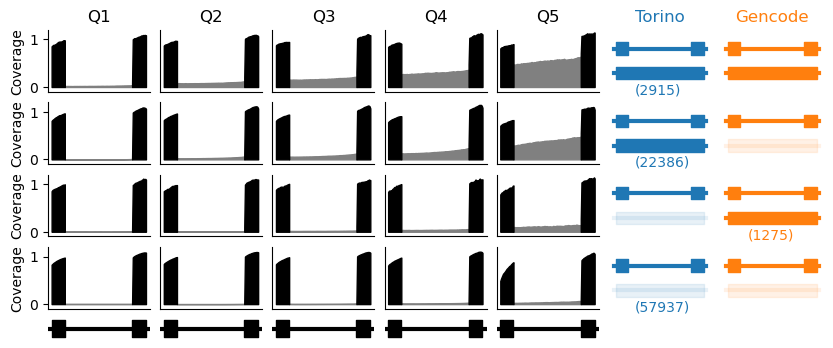

In [3]:
save(R.panel_intron_metaplot_quintiles(), 'intron_metaplot_quintiles')

### intron_metaplot_quintiles_vastdb
Source: `analysis/Retained_Introns_figure.ipynb cell 70`

(3158, 149)


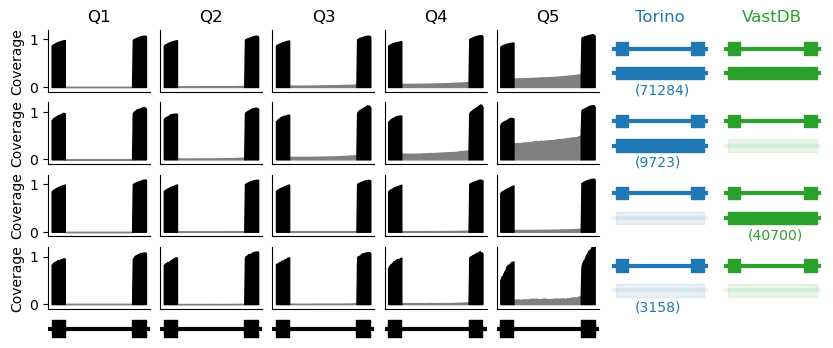

In [4]:
save(R.panel_intron_metaplot_quintiles_vastdb(), 'intron_metaplot_quintiles_vastdb')

### intron_metaplot_Liver
Source: `analysis/Retained_Introns_figure.ipynb cell 79`

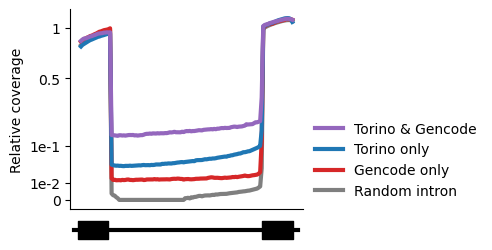

In [5]:
save(R.panel_intron_metaplot_Liver(), 'intron_metaplot_Liver')

### intron_barplot
Source: `analysis/Retained_Introns_figure.ipynb cell 137`

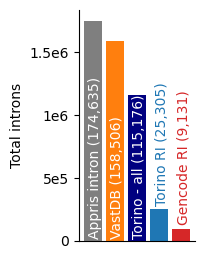

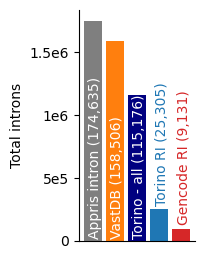

In [6]:
save(R.panel_intron_barplot(), 'intron_barplot')

### intron_cdf_Liver
Source: `analysis/Retained_Introns_figure.ipynb cell 144`

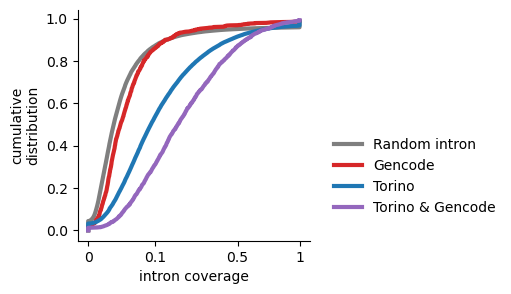

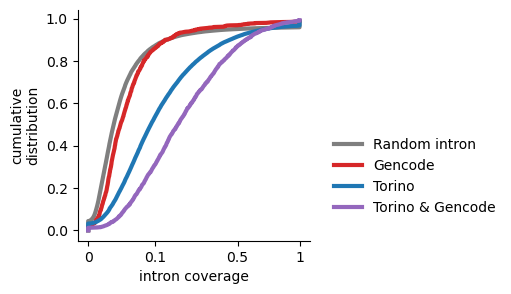

In [7]:
save(R.panel_intron_cdf_Liver(), 'intron_cdf_Liver')

## Retained-intron numbers

Every count below is recomputed here, and each row names the cell of
`analysis/Retained_Introns_figure.ipynb` that produced it. Run the cell to
render the table.

In [ ]:
Markdown(R.intron_retention_table())


## Cassette-exon numbers

Recomputed here for both gene sets; each row names the cell of
`analysis/CassetteExonsDeNovo.ipynb` it comes from. "exon only" asks whether
the cassette exon itself is annotated; "flanking exons also matching"
requires the flanks to agree too, which is why it is the smaller number.

Takes a couple of minutes -- it reads the Gencode exon annotation and the
VastDB event table, once per gene set.

In [ ]:
Markdown(K.cassette_table())


## Cassette exons

From `analysis/CassetteExonsDeNovo.ipynb`. The cassette exons are split
five ways -- annotated by both Gencode and VastDB, by one only, unannotated
but overlapping an annotated exon, and overlapping nothing -- and each
group gets a coverage metaplot across quintiles.

The Torino and Gencode cassette tables are read back from the bed files the
notebook wrote, not rebuilt by the per-gene loop that produced them.

### cassette_exons_brain_cortex
Source: `analysis/CassetteExonsDeNovo.ipynb cell 76`

In [ ]:
save(K.panel_cassette_exons_brain_cortex(), 'cassette_exons_brain_cortex')

### cassette_exons_heart_atrial_appendage
Source: `analysis/CassetteExonsDeNovo.ipynb cell 77`

In [ ]:
save(K.panel_cassette_exons_heart_atrial_appendage(), 'cassette_exons_heart_atrial_appendage')

### cassette_exons_liver
Source: `analysis/CassetteExonsDeNovo.ipynb cell 78`

In [ ]:
save(K.panel_cassette_exons_liver(), 'cassette_exons_liver')

### Exons per metaplot row

The five rows of the three cassette-exon metaplots above are annotation
groups; the five columns within a row are expression quintiles of that
row's exons. Source: `CassetteExonsDeNovo.ipynb` cell 76 (In[67]).

In [ ]:
Markdown(K.cassette_row_table())


### PCA_all
Source: `analysis/Retained_Introns_figure.ipynb cell 174`

In [8]:
# Needs ~6-8 GB: the EL table is 1.5 GB and the PCA copies and
# imputes it. Will not run on a login node -- uncomment under
# sinteractive --mem=16G.
# save(R.panel_PCA_all(), 'PCA_all')


### PCA_introns
Source: `analysis/Retained_Introns_figure.ipynb cell 175`

In [9]:
# Needs ~6-8 GB: the EL table is 1.5 GB and the PCA copies and
# imputes it. Will not run on a login node -- uncomment under
# sinteractive --mem=16G.
# save(R.panel_PCA_introns(), 'PCA_introns')


## Check the panels against the published figures

Renders each panel at the reference figure's own dpi and correlates the
two images. `EXACT` (corr 1.000) means it reproduces the published figure
pixel for pixel. Slow -- run it once, then comment it out.

In [10]:
# --- run once, then comment out ---
from SFigure2_verify import verify

verify()                                  # every panel except the PCAs
# verify(module='SFigure2_coverage')      # just one module
# verify('PCA_all')                       # a heavy one, by name


  skipping PCA_all, PCA_introns (needs ~8 GB; verify(heavy=True) or name it to include)



(57937, 149)
  EXACT   intron_metaplot_quintiles                  corr=1.000  (4162, 1745)  (10s)
(3158, 149)
  EXACT   intron_metaplot_quintiles_vastdb           corr=1.000  (4162, 1745)  (13s)
  EXACT   intron_metaplot_Liver                      corr=1.000  (2460, 1255)  (8s)
  EXACT   intron_barplot                             corr=1.000  (1021, 1295)  (0s)
  EXACT   intron_cdf_Liver                           corr=1.000  (2550, 1465)  (8s)
  EXACT   torino_missing_junctions_CGB8_factors      corr=1.000  (2425, 1640)  (1s)
  EXACT   torino_missing_junctions_CGB8_iso          corr=1.000  (7850, 2025)  (5s)
  EXACT   torino_missing_junctions_CGB8_torino_iso   corr=1.000  (7850, 1255)  (2s)

worst correlation: 1.000  -- every panel reproduces its published figure


## CGB8 coverage

From `analysis/CoveragePlots.ipynb`. The Torino factor tracks for CGB8 and
the Gencode and Torino isoform annotations beneath them. That notebook
redefines its own imported plotting functions several times, so these use
the definitions that were live when the panels ran (`In[29]`, `In[5]`) --
not the ones importable from `GeneticsPlotsFunctions`.

### torino_missing_junctions_CGB8_factors
Source: `analysis/CoveragePlots.ipynb cell 5`

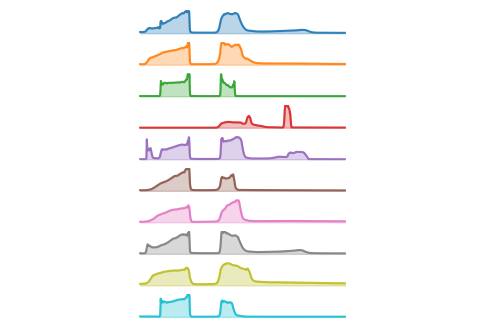

In [11]:
save(C.panel_torino_missing_junctions_CGB8_factors(), 'torino_missing_junctions_CGB8_factors')

### torino_missing_junctions_CGB8_iso
Source: `analysis/CoveragePlots.ipynb cell 6`

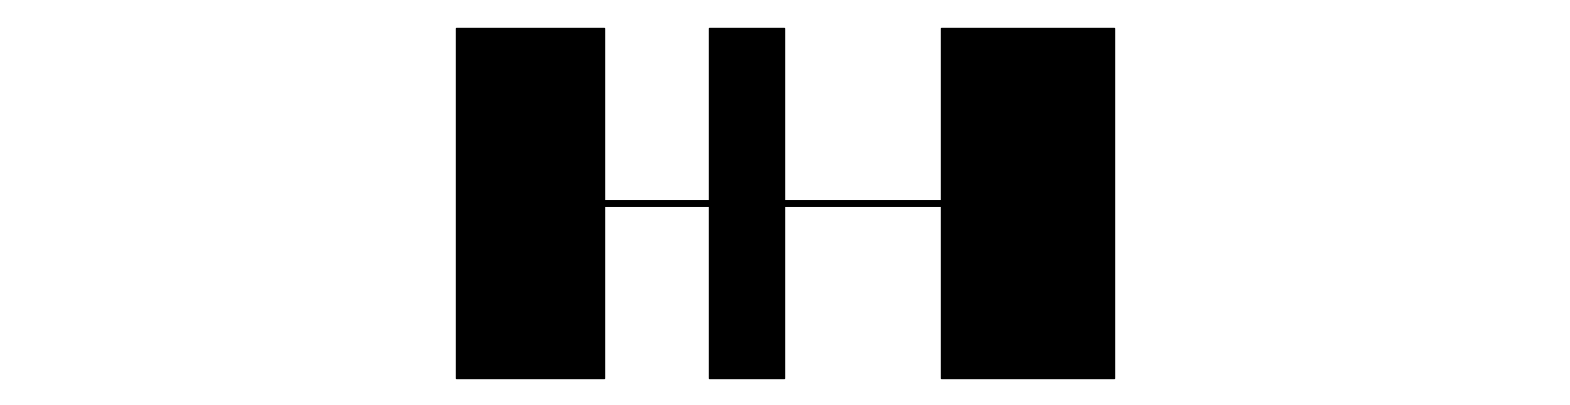

In [12]:
save(C.panel_torino_missing_junctions_CGB8_iso(), 'torino_missing_junctions_CGB8_iso')

### torino_missing_junctions_CGB8_torino_iso
Source: `analysis/CoveragePlots.ipynb cell 7`

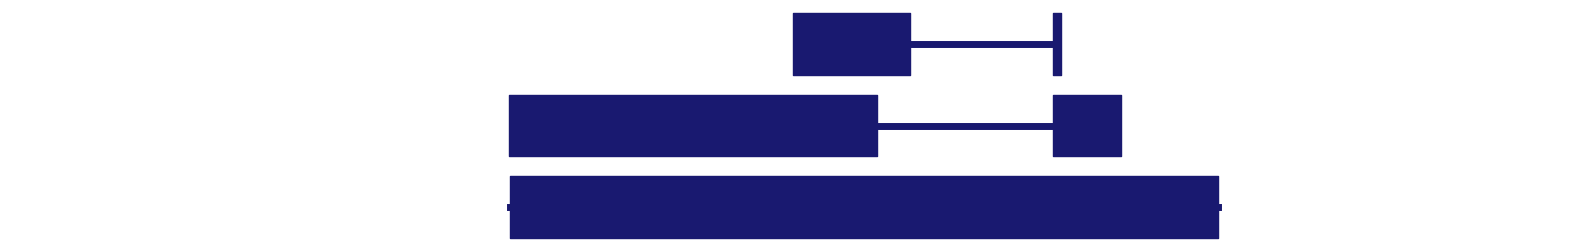

In [13]:
save(C.panel_torino_missing_junctions_CGB8_torino_iso(), 'torino_missing_junctions_CGB8_torino_iso')

## Full isoform upset (standalone)

Every isoform appears exactly once. Unlike the upsets in Figure 2, the
splicing-efficiency factors are a category rather than a filter, and so is
the leftover 'uncategorized' group -- both exclusive, so an isoform flagged
as an efficiency factor is never also counted as alt. Splicing. An
alternative first or last exon is its own category, kept separate from
alt. Splicing.

`min_subset_size` hides the tail of tiny intersections; the category totals
on the left still count every isoform.

In [ ]:
save(UP.panel_upset_full(), 'upset_full')

### Category sizes
Both gene sets, for the figure legend.

In [ ]:
Markdown(UP.upset_table())


## 3' UTR / polyadenylation numbers

Uncorrected and corrected side by side. Units are stated per row, which
matters here: a polyA **site** is a cluster of terminal-exon ends within
200 bp, while the notebook's original counts were per `gene:exon_start`,
and the two disagree. Both Torino populations are restricted to remove the
ambiguous cases -- APA to genes also labelled multi-site (71 dropped),
single-site to genes with exactly one `gene:end`.

Slow: the last two rows need the per-gene loadings loop.

In [ ]:
Markdown(U.polya_table())              # with_heatmap=False to skip the slow rows


### polyA barplot
Source: `analysis/UTR3.ipynb` cell 65

Bars are recomputed from the table above in the `gene:end` unit, so they
follow the gene subset. `U.panel_polyA_barplot_published()` draws the
original hardcoded version, which reproduces the published PNG exactly.

In [ ]:
save(U.panel_polyA_barplot(), 'polyA_barplot')

#### The published bar heights, for comparison

Cell 65 (In[158]) verbatim: the bar heights are literals and reproduce
`supp_fig/polyA/barplot.png` pixel for pixel. Kept alongside the
recomputed version above because one of its numbers (5,959 GENCODE APA
sites) appears in no cell output and is ten short of the 5,969 the data
gives, and because its unit is `gene:exon_start` rather than `gene:end`.

In [ ]:
save(U.panel_polyA_barplot_published(), 'polyA_barplot_published')


## Cassette exons (continued)

### cassette_exons_median_loadings
Source: `analysis/CassetteExonsDeNovo.ipynb cell 94`

Mean isoform usage per annotation group. Slow: rebuilds the
cassette-with-transcripts table, which was never written to disk.

In [ ]:
save(K.panel_cassette_exons_median_loadings(), 'cassette_exons_median_loadings')

### cassette_exons_torino_v_gencode_brain_cortex
Source: `analysis/CassetteExonsDeNovo.ipynb cell 128`

In [ ]:
save(K.panel_cassette_exons_torino_v_gencode_brain_cortex(), 'cassette_exons_torino_v_gencode_brain_cortex')

## VastDB brain cassette exons

### VastDB_cassette_exons_brain
Source: `analysis/Brain_Cassette_SSMD.ipynb cell 39`

SSMD of the Torino isoform carrying each brain-specific VastDB exon
against the one skipping it. Slow: two counting loops over the PSI table.

In [ ]:
save(B.panel_VastDB_cassette_exons_brain(), 'VastDB_cassette_exons_brain')

#### Exons per curve

The n shown in each legend. Both curves in a panel are drawn over the
same rows, because `.dropna()` is applied to the frame before a column
is selected. Corrected and uncorrected agree because all 441 genes
behind the curves already fall inside the 16,073-gene set: these events
need an SSMD result, so the genes are well-expressed ones that reached
K=10 -- the same criteria the corrected set selects on.

In [ ]:
Markdown(B.vastdb_ssmd_table())


## Annotation recovery

### torino_isoform_recovery_by_length
Source: `analysis/Appris_1.ipynb cell 6`

In [ ]:
save(A.panel_torino_isoform_recovery_by_length(), 'torino_isoform_recovery_by_length')

### torino_isoform_recovery_by_expression
Source: `analysis/Appris_1.ipynb cell 66`

In [ ]:
save(A.panel_torino_isoform_recovery_by_expression(), 'torino_isoform_recovery_by_expression')

### torino_annot_transcripts
Source: `analysis/Appris_1.ipynb cell 116`

In [ ]:
save(A.panel_torino_annot_transcripts(), 'torino_annot_transcripts')

### torino_missing_junctions_v2
Source: `analysis/Appris_1.ipynb cell 67`

The variant that matches the published figure. ~1 h: tabix-queries the
junction file once per gene without an annotation match.

In [ ]:
save(A.panel_torino_missing_junctions_v2(), 'torino_missing_junctions_v2')

### torino_missing_junctions
Source: `analysis/Appris_1.ipynb cell 61`

The In[397] variant, which has no published counterpart. Same ~1 h loop,
cached, so it is quick once `_v2` has run.

In [ ]:
save(A.panel_torino_missing_junctions(), 'torino_missing_junctions')

## 3' UTR heatmap

### polyA_heatmap
Source: `analysis/UTR3.ipynb cell 135`

Scaled usage of the longer 3' UTR across tissues. ~1 h: the per-gene
loadings loop, which nothing caches to disk.

In [ ]:
save(U.panel_polyA_heatmap(), 'polyA_heatmap')

### UTRs_cumulative

Long-read support for polyA sites: the cumulative share of site usage
against the share of sites, split by whether Torino and GENCODE agree.
Source: `UTR3.ipynb` cells 283 and 288 (In[1229], In[1280]).

The counts behind it come from nine ONT BAMs and live in
`figure_data/bam_counts.pkl`. If that file is missing the cell raises and
tells you to run `U.build_bam_counts()` once on a compute node; it will
not rebuild a pickle that already exists.

In [ ]:
save(U.panel_UTRs_cumulative(), 'UTRs_cumulative')


## Isoform usage by expression decile

Needs ~8 GB: `prepare_data` imputes the EL matrix. Run under
`sinteractive --mem=16G`. Which decile each panel uses is recorded in
`A.RANK_OF_PANEL` -- the notebook's execution counts collide and cannot
say, so the pairing is the one that reproduces the published PNGs.

### PCA_rank1
Source: `analysis/Appris_1.ipynb cell 41`

In [ ]:
# save(A.panel_PCA_rank1(), 'PCA_rank1')      # ~8 GB, uncomment under sinteractive


### heatmap_rank1
Source: `analysis/Appris_1.ipynb cell 43`

In [ ]:
# save(A.panel_heatmap_rank1(), 'heatmap_rank1')      # ~8 GB, uncomment under sinteractive


### PCA_rank20
Source: `analysis/Appris_1.ipynb cell 34`

In [ ]:
# save(A.panel_PCA_rank20(), 'PCA_rank20')      # ~8 GB, uncomment under sinteractive


### heatmap_rank20
Source: `analysis/Appris_1.ipynb cell 37`

In [ ]:
# save(A.panel_heatmap_rank20(), 'heatmap_rank20')      # ~8 GB, uncomment under sinteractive


## Variable APA across tissues

Where the polyA heatmap's numbers come from: the chain that produces
2,702 rows, and the brain-direction split shown by the row colours.

Source: `UTR3.ipynb` cells 125, 126, 128, 131 (In[83]-In[90]).

In [ ]:
Markdown(U.variable_apa_table())


## APA heatmaps

Three further heatmaps over the APA sites, alongside `polyA_heatmap`
above. All three plot relative 3' UTR usage per tissue, row-scaled,
with rows coloured by whether usage is higher in brain; they differ
in which population and which pair of ends they use.

| panel | population | ends compared |
|---|---|---|
| `polyA_heatmap_apa_sites` | genes behind the APA sites, strict subset | longest vs shortest |
| `polyA_heatmap_apa_extremes` | APA loci, terminal-exon groups recomputed | longest vs shortest |
| `polyA_heatmap_apa` | the same recomputed loci | the two most-used |


### Longest vs shortest APA site, per gene

Every end plotted is one of the APA sites; the table below
verifies that, shows how the gene set narrows, and gives the
brain split at four cutoffs.

In [ ]:
save(U.panel_polyA_heatmap_apa_sites(), 'polyA_heatmap_apa_sites')


In [ ]:
Markdown(U.apa_site_table())


### The same loci, the two most-used ends

Recomputed terminal-exon groups rather than the site table, so
the loci are not a strict subset. Included because the contrast
with the panel above isolates the effect of the pair choice:
comparing the dominant pair instead of the extremes drops the
brain fraction from ~85% to ~63%.

In [ ]:
save(U.panel_polyA_heatmap_apa(), 'polyA_heatmap_apa')


In [ ]:
save(U.panel_polyA_heatmap_apa_extremes(), 'polyA_heatmap_apa_extremes')
